<a href="https://colab.research.google.com/github/sanjardev23/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Menu detector")

Menu detector


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:

# _______________________
# Import Libraries
# _______________________
from google.colab import drive
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np

In [4]:
!cp -r /content/drive/MyDrive/food101_dataset /content/

In [5]:
# Define Dataset Path
DATASET_PATH = '/content/food101_dataset'
print('Dataset_path:', DATASET_PATH)

CUSTOM_CLASS_MAPPING = {
    # Drive folder name : class name
    'hamburger':      'hamburger',
    'chocolate_cake': 'dessert',
    'ice_cream':      'dessert',
    # 'pilaf':        'osh',     # folder is empty, uncomment after uploading images
    'pizza':          'pizza',
    'samosa':         'samosa',
}

CLASSES = sorted(set(CUSTOM_CLASS_MAPPING.values()))
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

print(NUM_CLASSES)
print(CLASSES)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

Dataset_path: /content/food101_dataset
4
['dessert', 'hamburger', 'pizza', 'samosa']


In [6]:
# --------------------
# Custom Dataset Class
# --------------------

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # print('images_length', len(self.images))
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)
        label = self.labels[idx]
        # print('label', label)
        try:
            image = Image.open(img_path).convert('RGB') # 3 Channel
            if image.mode == 'P' or image.mode == "RGBA": # png | gif | RGBA
              image = image.convert("RGBA").convert("RGB")
            else:
              image = image.convert("RGB")
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images)) #
        if self.transform:
            image = self.transform(image)
        return image, label

In [7]:
# --------------------
# Gather and Split Data
# --------------------
from collections import Counter

IMG_EXTS = ('.jpg', '.jpeg', '.png')
all_images = []

for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)
    if not os.path.isdir(class_path):
        raise FileNotFoundError(f"Missing class folder: {class_path}")

    count = 0
    for root, _, files in os.walk(class_path):
        for f in files:
            if f.lower().endswith(IMG_EXTS):
                all_images.append((os.path.join(root, f), CLASS_TO_IDX[mapped_class]))
                count += 1

    print(f"{original_class:15} -> {mapped_class:10} {count} images")
    if count == 0:
        raise ValueError(f"No images found in {class_path}")

print(Counter(CLASSES[l] for _, l in all_images))

np.random.shuffle(all_images)
split = int(0.8 * len(all_images))
train_data = all_images[:split]
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)
print('train:', len(train_images), '| val:', len(val_images))

hamburger       -> hamburger  1000 images
chocolate_cake  -> dessert    1000 images
ice_cream       -> dessert    1000 images
pizza           -> pizza      1000 images
samosa          -> samosa     1000 images
Counter({'dessert': 2000, 'hamburger': 1000, 'pizza': 1000, 'samosa': 1000})
train: 4000 | val: 1000


In [8]:

train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [9]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False,
                        num_workers=2, pin_memory=True)

In [10]:
# pretrained model
model = mobilenet_v2(weights="IMAGENET1K_V1") # pretrained model | lightweight | CNN | 1000 class | million
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES) # fine-tuning | backbone | model layer freeze

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)
model = model.to(device)

device cuda


In [12]:
criterion = nn.CrossEntropyLoss() # Loss Function | '70%' burger, '30%' osh
optimizer = optim.Adam(model.parameters(), lr=0.001)  # weight
torch.backends.cudnn.benchmark = True # Benchmark Setting | Trick | 10% - 20%

# Training the model

In [13]:
# -----------
# Training Loop (mixed precision bilan)
# -----------

NUM_EPOCHS = 5
best_accuracy = 0.0
SAVE_PATH = '/content/drive/MyDrive/menu_detector.pth'

scaler = torch.amp.GradScaler('cuda')  # mixed precision uchun

for epoch in range(NUM_EPOCHS):
  model.train() # train mode
  running_loss = 0.0

  print_every = 10

  for batch_idx, (images, labels) in enumerate(train_loader):
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)
    optimizer.zero_grad() # zero the gradient

    with torch.autocast(device_type='cuda', dtype=torch.float16):
      outputs = model(images) # Forward Pass
      loss = criterion(outputs, labels) # Calculate Loss

    scaler.scale(loss).backward() # Backward Pass
    scaler.step(optimizer) # weightlarni yangilash
    scaler.update()
    running_loss += loss.item()

    if (batch_idx + 1) % print_every == 0 or (batch_idx + 1) == len(train_loader):
      print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] | Step [{batch_idx+1}/{len(train_loader)}] | Loss: {running_loss/(batch_idx+1):.4f}")

  # Validation
  model.eval()
  correct = 0
  total = 0
  with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16):
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

  val_acc = 100 * correct / total # Calculate Validation Accuracy
  print(f'=== Epoch [{epoch+1}/{NUM_EPOCHS}] Completed | Val Accuracy: {val_acc:.2f}% ===\n')

  if val_acc > best_accuracy:
    best_accuracy = val_acc
    torch.save(model.state_dict(), SAVE_PATH)
    print("Saved new best model!")

Epoch [1/5] | Step [10/63] | Loss: 0.5726
Epoch [1/5] | Step [20/63] | Loss: 0.5459
Epoch [1/5] | Step [30/63] | Loss: 0.4882
Epoch [1/5] | Step [40/63] | Loss: 0.4572
Epoch [1/5] | Step [50/63] | Loss: 0.4391
Epoch [1/5] | Step [60/63] | Loss: 0.4085
Epoch [1/5] | Step [63/63] | Loss: 0.4037
=== Epoch [1/5] Completed | Val Accuracy: 89.80% ===

Saved new best model!
Epoch [2/5] | Step [10/63] | Loss: 0.1588
Epoch [2/5] | Step [20/63] | Loss: 0.1658
Epoch [2/5] | Step [30/63] | Loss: 0.1651
Epoch [2/5] | Step [40/63] | Loss: 0.1769
Epoch [2/5] | Step [50/63] | Loss: 0.1780
Epoch [2/5] | Step [60/63] | Loss: 0.1850
Epoch [2/5] | Step [63/63] | Loss: 0.1879
=== Epoch [2/5] Completed | Val Accuracy: 92.10% ===

Saved new best model!
Epoch [3/5] | Step [10/63] | Loss: 0.1378
Epoch [3/5] | Step [20/63] | Loss: 0.1505
Epoch [3/5] | Step [30/63] | Loss: 0.1490
Epoch [3/5] | Step [40/63] | Loss: 0.1507
Epoch [3/5] | Step [50/63] | Loss: 0.1557
Epoch [3/5] | Step [60/63] | Loss: 0.1505
Epoch [3

# menu_detector model usage

device: cuda
Upload one or more images of hamburger or hot dog:


Saving 54951.jpg to 54951.jpg


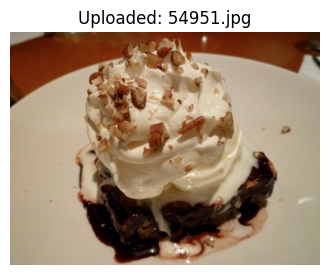

Prediction:
  ✅ dessert: 99.10%
  ✅ hamburger: 0.89%
  ✅ pizza: 0.01%
  ✅ samosa: 0.00%


In [19]:
# --------------------
# Required Imports
# --------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# --------------------
# Define Semantic Classes
# --------------------
CLASSES = ['dessert', 'hamburger', 'pizza', 'samosa']  # must match what cell 3 printed
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# --------------------
# Transform for Uploaded Images (no augmentations!)
# --------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# --------------------
# Load Model
# --------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# --------------------
# Upload & Predict
# --------------------
print("Upload one or more images of hamburger or hot dog:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  ✅ {label}: {confidence:.2f}%")